In [2]:
import re
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import wfdb              # 추가: 홀터 파형 파일(.hea/.dat)을 읽는 라이브러리
import neurokit2 as nk   # 추가: 심전도 필터링, R파 검출, HRV 계산 라이브러리

# ── 한글 폰트 설정 ───────────────────────────────────────────────
# WSL에 설치된 나눔고딕 파일을 matplotlib에 직접 등록
# (matplotlib은 처음 설치될 때 폰트 목록을 저장해두는데, 그 뒤에 설치된 나눔 폰트는 목록에 없어서 등록이 필요함)
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"     # 앞으로 그리는 모든 그래프의 기본 글꼴을 나눔고딕으로
plt.rcParams["axes.unicode_minus"] = False      # 한글 폰트에서 마이너스(−) 기호가 네모로 깨지는 것 방지

# 노트북이 notebooks/ 안에서 실행되든 프로젝트 루트에서 실행되든 data 폴더를 찾도록
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "music"

# 세미콜론 구분 + 소수점 쉼표, 엑셀 오류 문자열은 결측으로
na = ["#VALUE!", "#value", "#N/A", "NA", ""]
df = pd.read_csv(DATA / "subject-info.csv", sep=";", decimal=",", na_values=na)

print("shape:", df.shape)
print("Exit of the study:", df["Exit of the study"].value_counts(dropna=False).sort_index().to_dict())
print("Cause of death   :", df["Cause of death"].value_counts(dropna=False).sort_index().to_dict())

shape: (992, 103)
Exit of the study: {1.0: 11, 2.0: 20, 3.0: 266, nan: 695}
Cause of death   : {0: 726, 1: 61, 3: 94, 6: 100, 7: 11}


In [3]:
x = np.load("저장한파일.npy")
print(x.dtype, x.shape, x.nbytes / 1e6, "MB")


FileNotFoundError: [Errno 2] No such file or directory: '저장한파일.npy'

In [2]:
exit_col, cod_col = "Exit of the study", "Cause of death"

# 환자 ID 중복 확인 (환자 단위 분할의 전제)
assert df["Patient ID"].is_unique

# 제외 단계별 인원 기록 (보고서용)
flow = [("원본", len(df), int((df[cod_col] == 3).sum()))]

# 1) 추적탈락(1), 심장이식(2) 제외. 생존자는 Exit가 빈칸(NaN)이라 그대로 남음
base = df.loc[~df[exit_col].isin([1, 2])].copy()
flow.append(("추적탈락·이식 제외", len(base), int((base[cod_col] == 3).sum())))

# 2) 나이 ">89" 제외 후 숫자로 변환
is_89 = base["Age"].astype(str).str.strip() == ">89"
base = base.loc[~is_89].copy()
base["Age"] = pd.to_numeric(base["Age"])
flow.append(("나이 >89 제외", len(base), int((base[cod_col] == 3).sum())))

# 정답: SCD(3)=1, 나머지=0 (04b에서 생존(0)과 SCD(3)만 남김)
base["label_scd"] = (base[cod_col] == 3).astype(int)

flow = pd.DataFrame(flow, columns=["단계", "환자 수", "SCD"])
print(flow.to_string(index=False))
print("\n사망 원인별:", base[cod_col].value_counts().sort_index().to_dict())
print(f"SCD 비율: {base['label_scd'].mean():.3f}")


        단계  환자 수  SCD
        원본   992   94
추적탈락·이식 제외   961   94
 나이 >89 제외   960   94

사망 원인별: {0: 694, 1: 61, 3: 94, 6: 100, 7: 11}
SCD 비율: 0.098


In [3]:
HOLTER = Path("/mnt/c/data/music/Holter_ECG")

# 파형 헤더 파일(.hea)이 있는 환자만 표시
base["has_holter"] = base["Patient ID"].map(lambda pid: (HOLTER / f"{pid}.hea").exists())
holter_ids = base.loc[base["has_holter"], "Patient ID"].tolist()

print("960명 중 파형 있음:", len(holter_ids))
print("그중 생존+SCD (04b 모델에 쓸 사람):",
      int(base.loc[base["has_holter"], cod_col].isin([0, 3]).sum()))
print("사망 원인별:", base.loc[base["has_holter"], cod_col].value_counts().sort_index().to_dict())


960명 중 파형 있음: 0
그중 생존+SCD (04b 모델에 쓸 사람): 0
사망 원인별: {}


In [4]:
import wfdb   # PhysioNet 형식(.hea 헤더 + .dat 신호) 파일을 읽는 라이브러리

# ── 1) 헤더만 읽어서 기록 정보 확인 ──────────────────────────────
# 확장자 없이 "P0001"까지만 주면 wfdb가 P0001.hea와 P0001.dat를 알아서 찾음
rec_path = str(HOLTER / "P0001")

# rdheader: 신호(100MB)는 읽지 않고 헤더(텍스트 몇 줄)만 읽음 → 빠름
hdr = wfdb.rdheader(rec_path)
fs = hdr.fs   # 샘플링 속도: 1초에 몇 번 측정했는지 (200이면 1초에 200개 값)

# sig_name: 유도 이름 / sig_len: 전체 샘플 수 / units: 전압 단위
# 기록 시간(시간) = 전체 샘플 수 ÷ 초당 샘플 수 ÷ 3600
print("유도:", hdr.sig_name, "| 샘플링:", fs, "Hz | 길이:",
      round(hdr.sig_len / fs / 3600, 1), "시간 | 단위:", hdr.units)

# ── 2) 원하는 구간 10초만 읽기 ────────────────────────────────────
# 23시간 전체를 읽으면 메모리를 많이 쓰니까 필요한 부분만 읽음
# 기록 시작 직후는 전극이 자리잡기 전이라 잡음이 많을 수 있어서 1시간 뒤부터 읽음
start = 3600 * fs                                   # 1시간 = 3600초 × 200 = 720,000번째 샘플

# sampfrom ~ sampto 구간만 읽음: 10초 × 200 = 2000개 샘플
rec = wfdb.rdrecord(rec_path, sampfrom=start, sampto=start + 10 * fs)

# p_signal: 파일에 정수로 저장된 값을 실제 전압으로 바꾼 값 (헤더의 gain 100으로 나눔)
# 모양은 (2000, 3) → 행 = 시점 2000개, 열 = 유도 3개 (X, Y, Z)
sig = rec.p_signal

# ── 3) 세 유도를 위아래로 그리기 ──────────────────────────────────
# x축을 샘플 번호 대신 '초'로 표시: 0, 1/200, 2/200, ... 9.995초
t = np.arange(len(sig)) / fs

# 3행 1열 그래프. sharex=True로 세 그래프의 시간축을 맞춰서 같은 박동을 세로로 비교할 수 있게 함
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for i, ax in enumerate(axes):        # i = 0, 1, 2 → X, Y, Z 순서
    ax.plot(t, sig[:, i], lw=0.8)    # i번째 열(= i번째 유도)만 꺼내서 그림. lw = 선 굵기
    ax.set_ylabel(hdr.sig_name[i])   # 왼쪽에 유도 이름 표시
axes[-1].set_xlabel("초")            # 맨 아래 그래프에만 x축 이름 표시
plt.tight_layout()                   # 그래프끼리 글자가 겹치지 않게 간격 자동 조정
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/c/data/music/Holter_ECG/P0001.hea'

In [ ]:
# ── 여러 환자/시간대를 같은 방식으로 그리기 위해 함수로 만듦 ─────────
def plot_holter(pid, hour, seconds=10, lead="Y"):
    """pid 환자의 기록 시작 후 hour시간 지점부터 seconds초를 한 유도로 그림"""
    path = str(HOLTER / pid)
    h = wfdb.rdheader(path)                       # 샘플링 속도와 유도 이름을 알기 위해 헤더만 읽음
    s0 = int(hour * 3600 * h.fs)                  # 시작 샘플 번호 = 시간(초) × 초당 샘플 수
    r = wfdb.rdrecord(path, sampfrom=s0, sampto=s0 + seconds * h.fs)
    i = h.sig_name.index(lead)                    # "Y"가 몇 번째 열인지 찾음 (X=0, Y=1, Z=2)
    t = np.arange(r.sig_len) / h.fs               # x축: 0초부터 seconds초까지

    # CSV에서 이 환자의 리듬과 평균 RR을 꺼내 제목에 같이 표시 (그래프와 비교하려고)
    row = df.loc[df["Patient ID"] == pid].iloc[0]
    title = (f"{pid} | {hour}시간 지점 | 유도 {lead} | "
             f"CSV 리듬={row['Holter  rhythm ']} (0=동리듬, 1=심방세동, 3=페이스메이커) | "
             f"CSV 평균 RR={row['Average RR (ms)']}ms")

    fig, ax = plt.subplots(figsize=(14, 2.5))
    ax.plot(t, r.p_signal[:, i], lw=0.8)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("시간(초)")
    plt.tight_layout()
    plt.show()

# ── 1) 정상 리듬(동리듬) 환자: 규칙적인 박동이 어떻게 생겼는지 기준으로 보기 ──
# P0004: CSV 리듬 0(동리듬), 평균 RR 845ms → 10초에 약 12개 박동이 일정한 간격으로 보여야 함
plot_holter("P0004", hour=1)

# ── 2) P0001을 다른 시간대에서 보기: 1시간 지점만 빨랐던 건지 확인 ──
# 평균 RR 984ms면 10초에 10개 정도가 정상. 시간대마다 박동 수가 다른지 비교
for hr in [3, 8, 15]:
    plot_holter("P0001", hour=hr)

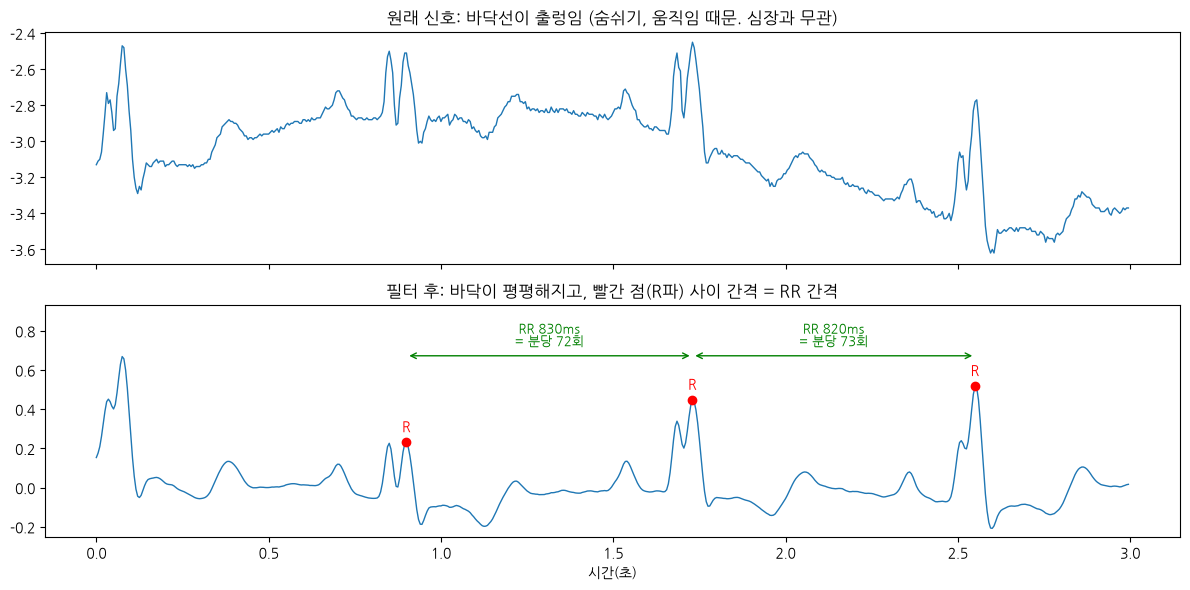

In [ ]:
# ── 그래프 읽는 연습: P0004의 3초에 R파와 RR 간격을 표시 ──────────────
pid = "P0004"
path = str(HOLTER / pid)
h = wfdb.rdheader(path)
fs = h.fs
s0 = 3600 * fs                                          # 1시간 지점
raw = wfdb.rdrecord(path, sampfrom=s0, sampto=s0 + 3 * fs).p_signal[:, h.sig_name.index("Y")]

# 필터 전/후 비교를 위해 정리된 신호도 만듦 (기준선 출렁임 제거)
clean = nk.ecg_clean(raw, sampling_rate=fs)
_, info = nk.ecg_peaks(clean, sampling_rate=fs)        # R파 위치 자동 검출
rpk = info["ECG_R_Peaks"]
t = np.arange(len(raw)) / fs

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# 위: 원래 신호 → 기준선이 출렁이는 모습
axes[0].plot(t, raw, lw=1)
axes[0].set_title("원래 신호: 바닥선이 출렁임 (숨쉬기, 움직임 때문. 심장과 무관)")

# 아래: 필터 후 신호 + R파 표시 + RR 간격 표시
axes[1].plot(t, clean, lw=1)
axes[1].plot(rpk / fs, clean[rpk], "ro", ms=6)          # R파 위치에 빨간 점
for k, p in enumerate(rpk):
    axes[1].annotate("R", (p / fs, clean[p]), textcoords="offset points",
                     xytext=(0, 8), ha="center", color="red")   # 점 위에 "R" 글자
for a, b in zip(rpk[:-1], rpk[1:]):                     # 이웃한 R파 두 개씩 짝지어서
    y = clean[rpk].max() * 1.3                          # 화살표를 그릴 높이 (R파보다 조금 위)
    axes[1].annotate("", xy=(b / fs, y), xytext=(a / fs, y),
                     arrowprops=dict(arrowstyle="<->", color="green"))  # 양쪽 화살표
    rr_ms = (b - a) / fs * 1000                         # RR 간격(ms)
    axes[1].text((a + b) / 2 / fs, y * 1.08, f"RR {rr_ms:.0f}ms\n= 분당 {60000 / rr_ms:.0f}회",
                 ha="center", color="green", fontsize=9)
axes[1].set_ylim(top=clean[rpk].max() * 1.8)            # 위쪽 글자가 잘리지 않게 여유를 둠
axes[1].set_title("필터 후: 바닥이 평평해지고, 빨간 점(R파) 사이 간격 = RR 간격")
axes[1].set_xlabel("시간(초)")
plt.tight_layout()
plt.show()


직접 만든 결과와 neurokit 결과의 최대 차이: 0.0


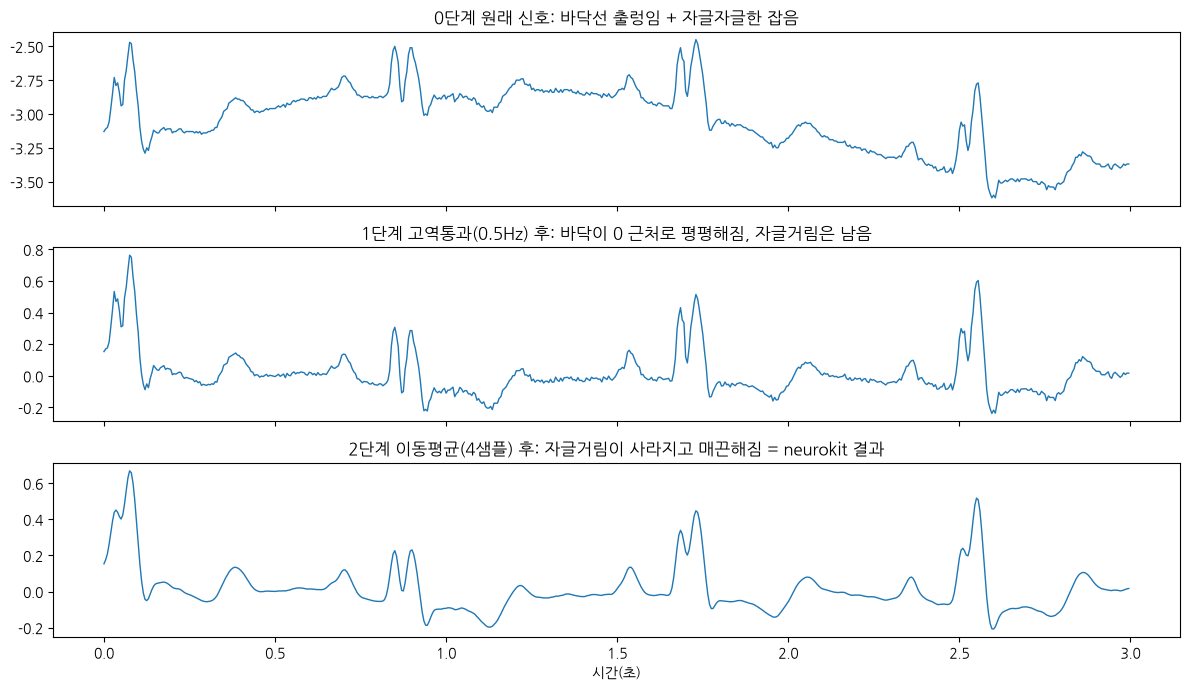

In [ ]:
from scipy.signal import butter, sosfiltfilt, filtfilt

# raw, fs, t는 바로 앞 연습 셀에서 만든 P0004의 3초 원래 신호를 그대로 씀

# ── 필터 ①: 0.5Hz 고역통과 (기준선 출렁임 제거) ───────────────────────
# butter(차수, 경계주파수, 종류): 0.5Hz보다 느린 움직임을 걸러내는 필터 설계도를 만듦
sos = butter(5, 0.5, btype="highpass", output="sos", fs=fs)
step1 = sosfiltfilt(sos, raw)            # 앞→뒤, 뒤→앞 두 번 적용 → R파 위치가 밀리지 않음

# ── 필터 ②: 50Hz 전원 잡음 제거 (이웃 4개 샘플 평균) ───────────────────
k = int(fs / 50)                         # 200Hz ÷ 50Hz = 4 → 50Hz 한 주기에 해당하는 샘플 수
step2 = filtfilt(np.ones(k), [k], step1) # 4개씩 더해서 4로 나눔 = 이동평균, 역시 양방향

# ── neurokit 결과와 같은지 확인 ─────────────────────────────────────────
nk_clean = nk.ecg_clean(raw, sampling_rate=fs)
print("직접 만든 결과와 neurokit 결과의 최대 차이:", np.abs(step2 - nk_clean).max())

# ── 단계별로 위아래 그리기 ─────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(t, raw, lw=1)
axes[0].set_title("0단계 원래 신호: 바닥선 출렁임 + 자글자글한 잡음")
axes[1].plot(t, step1, lw=1)
axes[1].set_title("1단계 고역통과(0.5Hz) 후: 바닥이 0 근처로 평평해짐, 자글거림은 남음")
axes[2].plot(t, step2, lw=1)
axes[2].set_title("2단계 이동평균(4샘플) 후: 자글거림이 사라지고 매끈해짐 = neurokit 결과")
axes[2].set_xlabel("시간(초)")
plt.tight_layout()
plt.show()


P0004: 5분 동안 R파 374개 | 평균 RR 801ms (분당 75회) | 최소 715ms | 최대 880ms | 표준편차 31ms


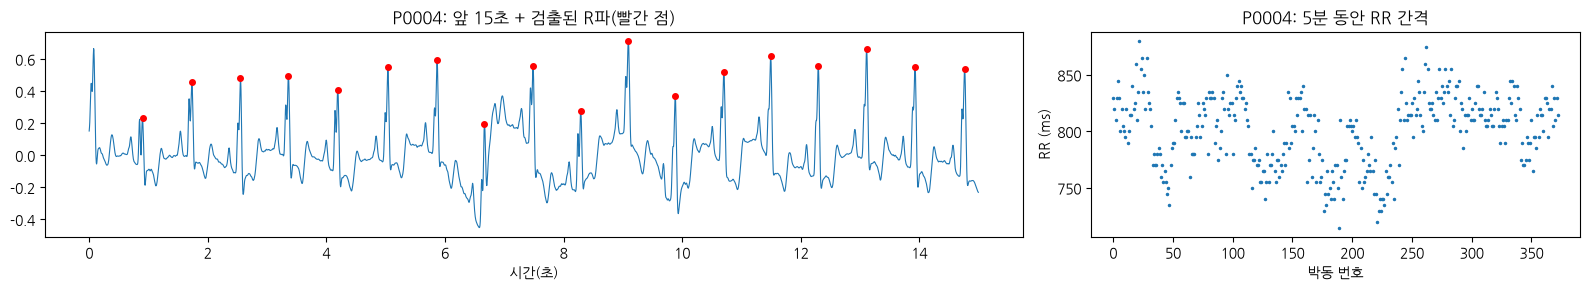

P0001: 5분 동안 R파 595개 | 평균 RR 504ms (분당 119회) | 최소 305ms | 최대 1250ms | 표준편차 151ms


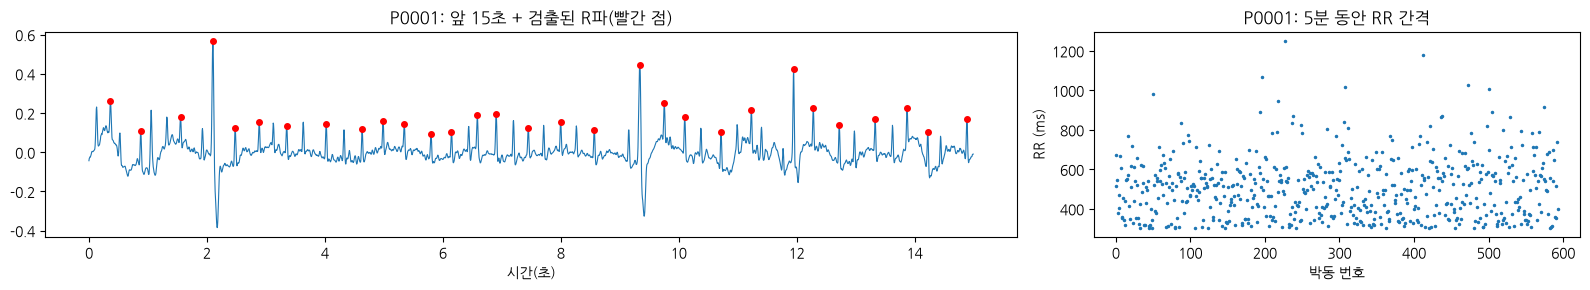

In [ ]:
# ── 1) 파형의 원하는 구간을 읽어오는 함수 ──────────────────────────────
# 앞으로 계속 쓸 함수라서 따로 만들어 둠
def load_segment(pid, start_sec, seconds, lead="Y"):
    """pid 환자의 start_sec초 지점부터 seconds초 동안 한 유도의 신호를 읽음"""
    path = str(HOLTER / pid)
    h = wfdb.rdheader(path)                                   # 샘플링 속도, 유도 이름 확인
    s0 = int(start_sec * h.fs)                                # 시작 샘플 번호 = 초 × 200
    r = wfdb.rdrecord(path, sampfrom=s0, sampto=s0 + int(seconds * h.fs))
    sig = r.p_signal[:, h.sig_name.index(lead)]               # Y 유도 열만 꺼냄
    sig = np.nan_to_num(sig)                                  # 전극이 떨어진 구간에 빈 값(NaN)이 있으면 0으로 (필터가 NaN에서 멈추지 않게)
    return sig, h.fs

# ── 2) 필터 + R파 검출 함수 (neurokit2 기본 설정) ──────────────────────
def detect_r(sig, fs):
    clean = nk.ecg_clean(sig, sampling_rate=fs)               # 0.5Hz 고역통과 + 4샘플 이동평균 (앞 셀에서 확인한 두 단계)
    _, info = nk.ecg_peaks(clean, sampling_rate=fs)           # 정리된 신호에서 R파 위치(샘플 번호)를 찾음
    return clean, info["ECG_R_Peaks"]                         # 정리된 신호, R파 위치 배열

# ── 3) 정상 리듬(P0004)과 심방세동(P0001)에 적용 ───────────────────────
for pid in ["P0004", "P0001"]:
    sig, fs = load_segment(pid, start_sec=3600, seconds=300)  # 1시간 지점부터 5분(300초) = 60,000개 샘플
    clean, rpk = detect_r(sig, fs)

    # RR 간격(ms) = 이웃한 R파 사이 샘플 수 ÷ 200 × 1000
    rr = np.diff(rpk) / fs * 1000

    # 결과 요약: 박동 수, 평균 RR(→ 분당 심박), 가장 짧은/긴 RR, 흔들림(표준편차)
    print(f"{pid}: 5분 동안 R파 {len(rpk)}개 | 평균 RR {rr.mean():.0f}ms (분당 {60000 / rr.mean():.0f}회) "
          f"| 최소 {rr.min():.0f}ms | 최대 {rr.max():.0f}ms | 표준편차 {rr.std():.0f}ms")

    # ── 그림 2개: 왼쪽은 앞 15초 파형 + 빨간 점, 오른쪽은 5분 동안의 RR 간격 변화 ──
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 3), gridspec_kw={"width_ratios": [2, 1]})

    # 왼쪽: 빨간 점이 R파마다 하나씩, 빠짐없이, 엉뚱한 곳 없이 찍혔는지 눈으로 확인
    n = 15 * fs                                               # 15초 = 3000개 샘플
    m = rpk[rpk < n]                                          # 15초 안의 R파만
    ax1.plot(np.arange(n) / fs, clean[:n], lw=0.8)
    ax1.plot(m / fs, clean[m], "ro", ms=4)
    ax1.set_title(f"{pid}: 앞 15초 + 검출된 R파(빨간 점)")
    ax1.set_xlabel("시간(초)")

    # 오른쪽: 박동 번호(가로) vs RR 간격(세로)
    #   정상 리듬 → 거의 일정한 높이의 띠
    #   심방세동 → 위아래로 넓게 흩어짐
    #   R파를 놓친 곳 → 위로 혼자 튀는 점 (RR이 두 배가 됨)
    #   잘못 검출한 곳 → 아래로 혼자 튀는 점 (RR이 반으로 쪼개짐)
    ax2.plot(rr, ".", ms=3)
    ax2.set_title(f"{pid}: 5분 동안 RR 간격")
    ax2.set_xlabel("박동 번호")
    ax2.set_ylabel("RR (ms)")

    plt.tight_layout()
    plt.show()


In [ ]:
import time

def nn_mask(rr):
    """관례 규칙으로 정상 간격(NN)인지 True/False: 300~2000ms + 바로 앞 간격과 20% 이내 (Malik 필터)"""
    prev = np.r_[np.nan, rr[:-1]]                      # 각 RR의 바로 앞 간격 (첫 RR은 앞이 없어 NaN → 자동 제외)
    return (rr >= 300) & (rr <= 2000) & (np.abs(rr - prev) <= 0.2 * prev)

def detect_r_full(pid):
    """기록 전체에서 X, Y, Z 세 유도를 모두 검출해보고, NN 비율이 가장 높은(가장 깨끗한) 유도의 R파를 돌려줌"""
    path = str(HOLTER / pid)
    rec = wfdb.rdrecord(path)                          # 세 유도를 모두 읽음 (약 400MB)
    fs = rec.fs

    # 빈 값(NaN) 확인: 지금까지 확인한 44명은 없었음. 있으면 알려주고 그 기록은 따로 보기
    if np.isnan(rec.p_signal).any():
        print(f"⚠ {pid}: 빈 값(NaN) {np.isnan(rec.p_signal).sum()}개 → 따로 확인 필요")

    best = None                                        # (NN 비율, 유도 이름, R파 위치) 중 가장 좋은 것
    ratios = {}                                        # 유도별 NN 비율 기록 (보고서, 확인용)
    for i, lead in enumerate(rec.sig_name):            # X, Y, Z 차례로
        clean = nk.ecg_clean(rec.p_signal[:, i], sampling_rate=fs)   # neurokit2 기본 필터
        _, info = nk.ecg_peaks(clean, sampling_rate=fs)              # neurokit2 기본 R파 검출
        rpk = np.asarray(info["ECG_R_Peaks"])
        ratio = nn_mask(np.diff(rpk) / fs * 1000).mean() * 100      # 이 유도로 검출했을 때 정상 간격 비율(%)
        ratios[lead] = round(ratio, 1)
        if best is None or ratio > best[0]:            # 지금까지 중 가장 깨끗하면 이 유도로 교체
            best = (ratio, lead, rpk)

    _, lead, rpk = best
    return rpk, fs, rec.sig_len, lead, ratios


# ── P0004에 적용 ──────────────────────────────────────────────────────
t0 = time.time()
rpk, fs, n, lead, ratios = detect_r_full("P0004")
print(f"처리 시간: {time.time() - t0:.1f}초")
print(f"유도별 NN 비율(%): {ratios} → 선택: {lead}")
print(f"기록 길이: {n / fs / 3600:.1f}시간 | 검출된 R파: {len(rpk):,}개")

# RR 간격(ms): 아직 아무것도 걸러내지 않은 원래 값
rr = np.diff(rpk) / fs * 1000

# ── CSV 홀터 요약값과 비교 (걸러내기 전) ─────────────────────────────────
# 주의: CSV에 "Average RR (ms)"가 두 개 있음. 끝에 공백이 있는 것은 20분 ECG, 없는 것이 홀터
row = df.loc[df["Patient ID"] == "P0004"].iloc[0]
compare = pd.DataFrame({
    "우리 계산": [rr.min(), rr.mean(), rr.max()],
    "CSV": [row["minimum RR (ms) "], row["Average RR (ms)"], row["maximum RR (ms)"]],
}, index=["최소 RR (ms)", "평균 RR (ms)", "최대 RR (ms)"]).round(0)
print(compare)

# 너무 짧거나 너무 긴 RR이 몇 개인지: 잘못 검출(짧음)이나 R파 놓침(긺)의 흔적
print(f"\n300ms 미만 RR: {(rr < 300).sum()}개 | 2000ms 초과 RR: {(rr > 2000).sum()}개")

# ── 그림: 23시간 동안 RR이 어떻게 변했는지 ─────────────────────────────
t_hr = rpk[1:] / fs / 3600            # 각 RR이 끝나는 시점을 '시간' 단위로 (가로축)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# 위: RR 간격 전체 (점 하나 = 박동 하나)
#   띠에서 위로 혼자 튀는 점 = R파를 놓쳤을 가능성, 아래로 튀는 점 = 잘못 검출했을 가능성
ax1.plot(t_hr, rr, ".", ms=0.5, alpha=0.3)
ax1.set_ylabel("RR (ms)")
ax1.set_title(f"P0004: 23시간 RR 간격 (유도 {lead}, 점 하나 = 박동 하나)")

# 아래: 1시간마다 평균 심박수 (분당) → 낮과 밤의 변화가 보이는지
hour_idx = t_hr.astype(int)
hourly_hr = pd.Series(60000 / rr).groupby(hour_idx).mean()
ax2.plot(hourly_hr.index + 0.5, hourly_hr.values, "o-")
ax2.set_ylabel("평균 심박 (분당)")
ax2.set_xlabel("기록 시작 후 시간")
ax2.set_title("1시간 평균 심박수")

plt.tight_layout()
plt.show()

In [ ]:
def rr_features(rpk, fs):
    """R파 위치 → 관례 규칙으로 정상 간격(NN) 선별 → 특징 9개"""

    rr = np.diff(rpk) / fs * 1000          # RR 간격(ms)
    t_end = rpk[1:] / fs                   # 각 RR이 끝나는 시점(초), SDANN의 5분 묶음용

    # ── 관례 규칙으로 정상 간격(NN) 고르기 (셀 7의 nn_mask와 같은 규칙) ──────
    # 300~2000ms 범위 + 바로 앞 간격과 20% 이내 (Malik 20% 필터)
    # 걸러지는 것: 잘못 검출, R파 놓침, 조기박동과 그 뒤 쉬는 간격
    nn = nn_mask(rr)
    x = rr[nn]                             # 정상 박동 간격(NN)

    # RMSSD, pNN50: 이웃한 두 간격이 모두 NN인 쌍의 차이만 사용
    pair = nn[:-1] & nn[1:]
    d = np.diff(rr)[pair]

    # SDANN (표준 정의): 기록을 5분씩 나눠 각 5분의 NN 평균을 구하고, 그 평균들의 표준편차
    m5 = pd.Series(x).groupby((t_end[nn] // 300).astype(int)).mean()

    return {
        "minimum RR":       x.min(),
        "Average RR":       x.mean(),
        "maximum RR":       x.max(),
        "RR range":         x.max() - x.min(),
        "Longest RR pause": rr[rr >= 300].max(),   # 관례 규칙이 없는 항목: 생리적 하한(300ms)만 적용. 잡음에 약함
        "SDNN":             x.std(),               # NN 전체의 표준편차
        "SDANN":            m5.std(),              # 5분 평균 NN들의 표준편차
        "RMSSD":            np.sqrt(np.mean(d ** 2)),        # 이웃 NN 차이의 제곱평균제곱근
        "pNN50":            np.mean(np.abs(d) > 50) * 100,   # 이웃 NN 차이가 50ms 넘는 비율(%)
        "NN 비율(%)":       nn.mean() * 100,       # 정상으로 인정된 RR 비율 (품질 확인용, CSV에는 없음)
    }

# CSV 열 이름 (끝 공백까지 정확히. "Average RR (ms) " 처럼 끝에 공백 있는 건 20분 ECG 열이라 다름)
CSV_COL = {
    "minimum RR": "minimum RR (ms) ", "Average RR": "Average RR (ms)", "maximum RR": "maximum RR (ms)",
    "RR range": "RR range (ms)", "Longest RR pause": "Longest RR pause (ms)",
    "SDNN": "SDNN (ms)", "SDANN": "SDANN (ms)", "RMSSD": "RMSSD (ms)", "pNN50": "pNN50 (%)",
}

def compare_with_csv(pid):
    """한 환자: R파 검출 → 특징 계산 → CSV와 나란히 표로"""
    rpk, fs, n, lead, ratios = detect_r_full(pid)   # 셀 7 함수: 가장 깨끗한 유도로 R파 검출
    feat = rr_features(rpk, fs)
    row = df.loc[df["Patient ID"] == pid].iloc[0]
    table = pd.DataFrame({
        "우리 계산": feat,
        "CSV": {k: row[c] for k, c in CSV_COL.items()},   # NN 비율은 CSV에 없어서 빈칸
    }).round(1)
    table["차이(%)"] = ((table["우리 계산"] - table["CSV"]) / table["CSV"] * 100).round(1)
    print(f"{pid} | 유도 {lead} {ratios} | CSV 리듬={row['Holter  rhythm ']} (0=동리듬, 1=심방세동)")
    print(table, "\n")

compare_with_csv("P0004")

In [ ]:
# ── 1) 검증용 10명 뽑기: 리듬별로 정해진 수만큼 무작위 ─────────────────
RHYTHM_COL = "Holter  rhythm "                     # CSV 열 이름 (중간 공백 2개, 끝 공백 1개)
hol = base.loc[base["has_holter"]]                 # 파형 있는 905명 (셀 3에서 만든 has_holter 사용)

picks = []
for code, k in [(0, 6), (1, 2), (3, 2)]:           # 0=동리듬 6명, 1=심방세동 2명, 3=페이스메이커 2명
    pool = hol.loc[hol[RHYTHM_COL] == code, "Patient ID"]
    picks += pool.sample(k, random_state=42).tolist()   # random_state 고정 → 다시 돌려도 같은 사람
print("검증 대상:", picks)

# ── 2) 10명 모두 계산해서 하나의 긴 표로 모으기 ──────────────────────────
rows = []
for pid in picks:
    t0 = time.time()
    rpk, fs, n, lead, ratios = detect_r_full(pid)  # 셀 7 함수: 가장 깨끗한 유도로 R파 검출
    feat = rr_features(rpk, fs)                    # 셀 8 함수: 관례 규칙으로 걸러내고 특징 9개 계산
    csv_row = df.loc[df["Patient ID"] == pid].iloc[0]
    for k, c in CSV_COL.items():                   # 특징 하나당 한 줄: (환자, 특징, 우리 값, CSV 값)
        rows.append({"환자": pid, "리듬": csv_row[RHYTHM_COL], "특징": k,
                     "우리": feat[k], "CSV": csv_row[c]})
    print(f"{pid} 완료 ({time.time() - t0:.1f}초) | 유도 {lead} {ratios} | NN 비율 {feat['NN 비율(%)']:.1f}%")

long = pd.DataFrame(rows)
long["차이(%)"] = (long["우리"] - long["CSV"]) / long["CSV"] * 100

# ── 3) 환자 × 특징 표: 한눈에 보기 (칸 = 차이 %) ──────────────────────────
# pivot: 긴 표(환자·특징마다 한 줄)를 환자가 행, 특징이 열인 표로 바꿈
wide = long.pivot(index=["환자", "리듬"], columns="특징", values="차이(%)")[list(CSV_COL)]
print("\n[환자별 차이(%)]  NaN = CSV에 값이 없음")
print(wide.round(1).to_string())

# ── 4) 특징별 요약: 10명 기준으로 얼마나 맞는지 ──────────────────────────
# 차이 중앙값: 우리 값이 CSV보다 대체로 크거나 작은지 (치우침)
# 절대차이 중앙값: 방향과 상관없이 보통 몇 % 어긋나는지 (정확도)
# 상관계수: 환자들 사이의 순서가 CSV와 같은지 (모델에는 이게 가장 중요)
summary_rows = []
for k in CSV_COL:
    g = long[(long["특징"] == k) & long["CSV"].notna()]   # CSV에 값이 있는 환자만
    summary_rows.append({
        "특징": k,
        "환자 수": len(g),
        "차이 중앙값(%)": g["차이(%)"].median(),
        "절대차이 중앙값(%)": g["차이(%)"].abs().median(),
        "상관계수": g["우리"].corr(g["CSV"]) if len(g) >= 3 else np.nan,   # 3명 미만이면 계산 안 함
    })
summary = pd.DataFrame(summary_rows).set_index("특징")
print("\n[특징별 요약]")
print(summary.round(2).to_string())